# Proyecto final · Retrasos de vuelos en Estados Unidos
### Especialización en Analítica y Ciencia de Datos · Machine Learning · Universidad EIA

**Autores:** Sebastián Olaya Pérez · Carlos Daniel Bedoya Moreno · Santiago Felipe Espinel León · Julián Alzate Aristizábal

Una fila es un **vuelo programado**. La pregunta es si llegará **15 minutos o más tarde** que el itinerario (`ARR_DEL15 = 1`, estándar oficial del U.S. DOT). La predicción se emite **a la hora de salida programada**, así que solo puede usar lo que ya se sabe en ese instante: itinerario, ruta, calendario, congestión programada del aeropuerto y cómo venía la aeronave en su tramo anterior. Todo lo que se mide *durante* o *después* del vuelo es **fuga** y está prohibido.

**Periodo:** 1 de junio de 2025 — 31 de mayo de 2026 (12 meses calendario, un ciclo estacional completo).

**Recorrido:** 1 ¿ML? · 2 Datos · 3 Limpieza · 4 Columnas · 5 Modelos · 6 Evaluación (los seis pasos de la rúbrica).

> **Cómo se corre:** `Kernel → Restart & Run All` con `MODO_RAPIDO = True` en `src/config.py`. Semilla fija (`SEMILLA = 42`): los números coinciden con los de las láminas.


In [1]:
# Todo el código vive en src/. El notebook solo cuenta la historia.
import sys, json, time
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config as cfg
from src import datos, columnas, modelos, evaluacion

np.random.seed(cfg.SEMILLA)
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 60)

print("Raíz    :", RAIZ)
print("Periodo :", cfg.MES_INICIO, "→", cfg.MES_FIN)
print("Modo    :", "RÁPIDO (exposición)" if cfg.MODO_RAPIDO else "COMPLETO (informe)")
print("Semilla :", cfg.SEMILLA, "| XGBoost disponible:", modelos.HAY_XGB)


Raíz    : c:\Users\julia\OneDrive\Escritorio\Proyecto-final-Machine-Learning
Periodo : 2025-06 → 2026-05
Modo    : RÁPIDO (exposición)
Semilla : 42 | XGBoost disponible: True


---
## 1 · ¿Hace falta machine learning?

Un retraso cuesta combustible, tripulación, puertas y conexiones perdidas, y el US DOT publica rankings de puntualidad: tiene costo económico y reputacional. Con el aviso **a la hora de salida** la aerolínea reasigna puertas y el pasajero reorganiza su conexión, así que la predicción sirve para actuar.

| Pregunta | Respuesta |
|---|---|
| ¿Hay un patrón que aprender? | **Sí.** El retraso depende de la hora, del aeropuerto, de la aerolínea, de la congestión programada y de si la aeronave venía retrasada. Se verifica en el paso 4. |
| ¿Hay etiqueta? | **Sí.** `ARR_DEL15` viene en los datos (1 = llegó con ≥ 15 min de retraso). No hay que inventarla. |
| ¿Hay suficientes datos? | **Sí**, millones de vuelos en 12 meses. Se confirma al cargar, en el paso 2. |
| ¿Una regla a mano ya basta? | **Se mide, no se supone.** Se formula abajo, se calibra en el paso 5 y compite en la misma tabla. |
| ¿Cuánto cuesta equivocarse? | Un **falso negativo** (no avisar un retraso) hace perder una conexión; un **falso positivo** genera una alerta inútil. El primero cuesta más, así que vigilamos **recall** y **F1**, no la exactitud. |

**La regla a mano:** *«si el vuelo sale a las HH:00 o después, llegará retrasado»*. La hora `HH` se busca **solo con el entrenamiento** en el paso 5. La regla está escrita como estimador de sklearn (`modelos.ReglaManual`) para que pase por la misma validación cruzada: la comparación es justa.

**Por qué la exactitud no sirve aquí.** Cerca del 80 % de los vuelos llega a tiempo: decir siempre «puntual» ya acierta ese 80 % sin encontrar un solo retraso. La métrica principal es el **AUC**, acompañada de **PR-AUC**, **recall** y **F1**.


---
## 2 · Los datos

| | |
|---|---|
| **Página** | https://www.kaggle.com/datasets/umerhafeezsiddiqui/2021-2026-us-flights |
| **Quién publica** | Recopilado en Kaggle por `umerhafeezsiddiqui` a partir del reporte *On-Time Performance* del **Bureau of Transportation Statistics (BTS)**, del U.S. Department of Transportation. Los nombres de columna (`FL_DATE`, `OP_UNIQUE_CARRIER`, `CRS_DEP_TIME`, `ARR_DEL15`…) son los del formulario oficial del BTS. |
| **Licencia** | *U.S. Government Work*: dominio público. Reproducido en Kaggle sin restricciones adicionales. |
| **Cómo se descarga** | Un CSV por mes (`Jun-2025.csv`, …, `May-2026.csv`) desde la pestaña *Data* de Kaggle. Se dejan en `data/raw/`. |
| **Qué es una fila** | **Un vuelo programado**: un tramo origen → destino, de una aerolínea, en una fecha. Incluye los que terminaron cancelados o desviados. |
| **Etiqueta** | `retraso15 = ARR_DEL15 = 1` si el vuelo llegó con **≥ 15 min** de retraso (definición oficial del DOT). |

**Complejidad del origen (rúbrica, criterio «complejidad» 25 %).** No es un archivo ya limpio: son **12 CSV mensuales** de ~85 MB que hay que unir, recortar al periodo y convertir a tipos pequeños para que quepan en memoria. Además, la **tabla principal la armamos nosotros**: la rotación de cada aeronave (el retraso de su tramo anterior) no viene en los datos; se deduce ordenando por `TAIL_NUM` y reconstruyendo los husos horarios desde el itinerario, sin tabla externa.


In [2]:
df = datos.cargar()          # lee data/raw/*.csv por bloques y guarda caché en parquet
print(f"\nTabla cruda: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print("Rango de fechas:", df.fecha.min().date(), "→", df.fecha.max().date())
display(df.head(4))


Caché encontrada: vuelos_2025-06_2026-05.parquet

Tabla cruda: 7,786,702 filas × 19 columnas
Rango de fechas: 2025-06-01 → 2026-05-31


,YEAR,MONTH,DAY_OF_MONTH,FL_DATE,OP_UNIQUE_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_DELAY,CRS_ARR_TIME,ARR_DELAY,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE,fecha
0,2026,4,1,04-01-26 00:00,9E,N131EV,4969,XNA,LGA,1150,68.0,1547,69.0,1.0,0,0,177.0,1147,2026-04-01
1,2026,4,1,04-01-26 00:00,9E,N131EV,5348,LGA,ORF,1633,70.0,1803,106.0,1.0,0,0,90.0,296,2026-04-01
2,2026,4,1,04-01-26 00:00,9E,N131EV,5348,ORF,LGA,1843,NaN,2012,NaN,NaN,1,0,89.0,296,2026-04-01
3,2026,4,1,04-01-26 00:00,9E,N131EV,5402,DSM,MSP,655,-9.0,814,-20.0,0.0,0,0,79.0,232,2026-04-01


### 2.1 · Cobertura mensual

Si falta un mes, la validación temporal queda sesgada. Verificamos que estén los 12 meses del estudio y que el volumen sea comparable.

Meses esperados: 12 · presentes: 12 · faltantes: ninguno


,periodo,vuelos,dias,aerolineas,aeropuertos
0,2025-06,674179,30,20,360
1,2025-07,696049,31,20,360
2,2025-08,666242,31,20,363
3,2025-09,621601,30,20,360
4,2025-10,668332,31,20,361
5,2025-11,630188,30,20,357
6,2025-12,644987,31,20,359
7,2026-01,602953,31,19,359
8,2026-02,568789,28,19,362
9,2026-03,675500,31,19,361


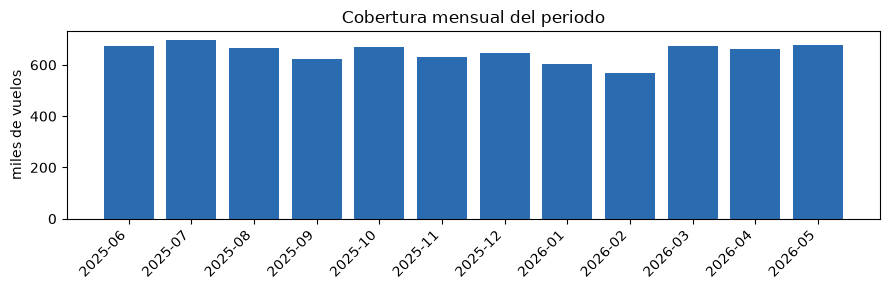

In [3]:
cobertura = datos.cobertura_mensual(df)
display(cobertura)

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(cobertura["periodo"], cobertura["vuelos"] / 1_000, color=evaluacion.AZUL)
ax.set(title="Cobertura mensual del periodo", ylabel="miles de vuelos")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()


---
## 3 · Limpieza

Cada decisión se imprime **con su conteo**. La regla del paso: aquí solo se arregla lo que es un hecho objetivo de los datos (formatos, duplicados, filas imposibles). **Nada que se aprenda de los datos —medias, medianas, codificaciones— se hace aquí**: todo eso vive dentro del `Pipeline` del paso 5, que se reajusta en cada pliegue (así ningún estimador «ve» las filas de validación).

1. **Nulos.** Las cinco columnas de *causas* del retraso (`CARRIER_DELAY`, `WEATHER_DELAY`, `NAS_DELAY`, `SECURITY_DELAY`, `LATE_AIRCRAFT_DELAY`) superan el 50 % de nulos porque **solo se llenan cuando ya hubo retraso**: además de vacías son fuga. **Ni se leen** del CSV (ver `cfg.COLS_CRUDAS`).
2. **Cancelados y desviados.** Un vuelo que nunca llegó **no tiene retraso de llegada y no tiene etiqueta**. ⚠ *El error que hay que evitar* es taparlos con la mediana: eso le inventa una etiqueta falsa y, peor, una hora de llegada al tramo anterior de la aeronave, que es justamente la variable más predictiva del paso 4. Se marcan con `tiene_etiqueta` y **se filtran al final del paso 4**, porque sus horarios programados sí cuentan para la congestión y la rotación.
3. **Itinerarios imposibles.** Sin hora, duración o distancia no hay vuelo que predecir: se eliminan.
4. **Duplicados exactos.** Llave: fecha + aerolínea + número de vuelo + origen + destino + hora programada.
5. **Formatos.** Fecha reconstruida desde `YEAR/MONTH/DAY_OF_MONTH` (evita el `FL_DATE` ambiguo). Horas `hhmm` a minutos con `% 1440`, de modo que el `2400` del BTS cae en `0`.
6. **Atípicos.** Los retrasos de más de un día son reales y no se borran. Como *variable* (`ret_prev_llegada`) se recortan a `[-60, 360]` con **constantes fijas**, no con percentiles calculados sobre los datos: por eso el recorte no introduce fuga.


In [4]:
antes = datos.foto(df, "ANTES")
df_limpio, bitacora = datos.limpiar(df)
despues = datos.foto(df_limpio, "DESPUÉS")

print("Bitácora de la limpieza:")
for k, v in bitacora.items():
    print(f"  {k:25s} {v}")

antes_despues = pd.concat([antes, despues], axis=1)
antes_despues["cambio"] = antes_despues["DESPUÉS"] - antes_despues["ANTES"]
display(antes_despues)
antes_despues.to_csv(cfg.RESULTADOS / "tabla_antes_despues.csv")


Bitácora de la limpieza:
  cancelados                145007
  desviados                 21637
  sin_etiqueta              166645
  coherencia_etiqueta       1.0
  tasa_retraso              0.22443388402462006
  itinerarios_invalidos     18
  duplicados                0
  filas_antes               7786702
  filas_despues             7786684


,ANTES,DESPUÉS,cambio
filas,7786702.00,7786684.000,-18.000
columnas,19.00,20.000,1.000
memoria (GB),0.86,0.919,0.059
duplicados,0.00,0.000,0.000
cancelados,145007.00,145002.000,-5.000
desviados,21637.00,21626.000,-11.000
% nulos CRS_ELAPSED_TIME,0.00,0.000,0.000
% nulos ARR_DELAY,2.14,2.140,0.000
% nulos ARR_DEL15,2.14,2.140,0.000
% nulos TAIL_NUM,0.30,0.300,0.000


In [5]:
# Inventario de nulos: enseña por qué las 5 columnas de causas son fuga (>50% nulos).
display(datos.nulos_por_columna(df_limpio))

# Resumen de atípicos: valores extremos son reales (vuelos perdidos por tormentas).
display(datos.resumen_atipicos(df_limpio))


,% nulos
ARR_DELAY,2.14
ARR_DEL15,2.14
DEP_DELAY,1.80
TAIL_NUM,0.30


,count,mean,std,min,1%,50%,99%,max
ARR_DELAY,7620055.0,8.549687,61.510223,-109.0,-37.0,-6.0,231.0,4336.0
CRS_ELAPSED_TIME,7620055.0,145.353248,71.444745,9.0,51.0,128.0,374.0,1202.0
DISTANCE,7620055.0,805.577426,592.634750,31.0,93.0,646.0,2611.0,5095.0


---
## 4 · Columnas

**Regla de oro anti-fuga:** una columna entra SOLO si su valor se conoce a la hora de salida programada. Entra todo lo que sale del itinerario; no entra nada que se mida durante o después del vuelo.

Creamos las columnas más informativas del proyecto (ninguna viene en los datos originales):

- `ret_prev_llegada` + `prev_disponible` — **propagación del retraso**: cuánto se demoró el tramo anterior del mismo avión, solo si **ya aterrizó antes** de la salida programada de este vuelo. La bandera `prev_disponible` captura el faltante como información.
- `holgura_prog` — minutos entre la llegada programada del tramo previo y la salida programada de este vuelo.
- `vuelos_origen_hora` / `vuelos_destino_hora` — **congestión programada**: cuántos vuelos había agendados en ese aeropuerto en esa hora. Se cuenta sobre vuelos PROGRAMADOS (incluye los que luego se cancelan), porque las cancelaciones no se conocen de antemano.
- `tramo_del_dia` — qué número de tramo del día es (el 4º vuelo de un avión sale más tarde que el 1º).
- `dias_a_festivo` — días al festivo federal más cercano (las vísperas saturan los aeropuertos).

Además armamos columnas de calendario y de hora: `hora_sal`, `hora_sal_dec`, `hora_lleg`, `dia_semana`.


In [6]:
df_full = columnas.crear_columnas(df_limpio)
tabla = columnas.tabla_modelado(df_full)
print(f"Tabla final para modelado: {len(tabla):,} filas × {tabla.shape[1]} columnas")
print(f"Tasa de retraso          : {tabla[cfg.OBJETIVO].mean():.4f} "
      f"({tabla[cfg.OBJETIVO].mean()*100:.2f}%)")
display(tabla.head(3))


Tabla final para modelado: 7,620,055 filas × 19 columnas
Tasa de retraso          : 0.2244 (22.44%)


,fecha,retraso15,DEP_DELAY,hora_sal,DISTANCE,CRS_ELAPSED_TIME,hora_sal_dec,hora_lleg,dias_a_festivo,vuelos_origen_hora,vuelos_destino_hora,tramo_del_dia,holgura_prog,ret_prev_llegada,prev_disponible,OP_UNIQUE_CARRIER,ORIGIN,DEST,dia_semana
0,2026-04-01,1,68.0,11,1147,177,11.833333,15,15,5,31,3,41.0,-3.0,1,9E,XNA,LGA,2
1,2026-04-01,1,70.0,16,296,90,16.549999,18,15,31,6,4,46.0,NaN,0,9E,LGA,ORF,2
2,2026-04-01,0,-9.0,6,232,79,6.916667,8,15,6,23,1,610.0,149.0,1,9E,DSM,MSP,2


### 4.1 · Decisiones por columna (tabla «antes y después»)

Cada columna del CSV crudo tiene un destino explícito: entra, se transforma, se usa pero no entra, o se descarta por fuga.

In [7]:
dec = columnas.tabla_decisiones()
display(dec)
dec.to_csv(cfg.RESULTADOS / "tabla_columnas.csv", index=False)


,columna original,decisión,en qué se convierte
0,YEAR / MONTH / DAY_OF_MONTH / FL_DATE,se transforma,fecha · dia_semana · dias_a_festivo
1,OP_UNIQUE_CARRIER,ENTRA (categórica),codificación por objetivo dentro del Pipeline
2,ORIGIN / DEST,ENTRAN (categóricas),codificación por objetivo dentro del Pipeline
3,CRS_DEP_TIME,se transforma,hora_sal · hora_sal_dec
4,CRS_ARR_TIME,se transforma,hora_lleg · desfase horario
5,CRS_ELAPSED_TIME / DISTANCE,ENTRAN (numéricas),imputación y escalado dentro del Pipeline
6,TAIL_NUM,"se usa, no entra",ret_prev_llegada · holgura_prog · tramo_del_dia
7,OP_CARRIER_FL_NUM,DESCARTADA · identificador,solo sirve para detectar duplicados
8,ARR_DEL15,ES LA ETIQUETA,retraso15
9,ARR_DELAY,DESCARTADA · fuga (se mide durante o después d...,el del tramo ANTERIOR sí se usa: ret_prev_llegada


### 4.2 · Primera barrera anti-fuga

Antes de modelar, un `assert` hace fallar el notebook si alguna columna prohibida se cuela entre las variables. Es una barrera defensiva: más vale una excepción temprana que un AUC inflado por error.

In [8]:
columnas.verificar_sin_fuga()


Verificación anti-fuga superada: 11 numéricas + 4 categóricas, ninguna prohibida.


### 4.3 · Experimento controlado de faltantes 

`ret_prev_llegada` tiene NaN cuando no hay tramo anterior o éste aún no había aterrizado. Para elegir el mejor imputador:
1. Tomamos los vuelos donde la variable SÍ existe.
2. Ocultamos a propósito el 25 % de esos valores.
3. Estimamos con cuatro métodos (media, mediana global, mediana por hora, regresión HistGB).
4. Gana el que menos se equivoca en MAE.

Esto se hace **antes** de modelar, pero el imputador que entra al Pipeline del paso 5 es el estándar de sklearn (`SimpleImputer(strategy="median")`), que se reajusta en cada pliegue. El experimento aquí sirve para argumentar la decisión.

In [9]:
mae_imp = columnas.comparar_imputacion(df_full)
print(f"Desviación típica de ret_prev_llegada: {mae_imp.attrs['desviacion']:.2f} min")
display(mae_imp)
mae_imp.to_csv(cfg.RESULTADOS / "comparacion_imputacion.csv")


Desviación típica de ret_prev_llegada: 36.45 min


,MAE (min)
Mediana por hora de salida,18.438
Mediana global,18.574
Regresión (HistGB),19.941
Media global,20.251


### 4.4 · Demostración empírica de fuga

Dejamos entrar a propósito `DEP_DELAY` (retraso de salida real, que solo se conoce después del despegue) y medimos el AUC. El salto que aparece es la **firma de la fuga**: en producción no se puede obtener ese número. Por eso `DEP_DELAY` y las demás columnas de la familia están en `cfg.PROHIBIDAS`.

In [10]:
demo_fuga = evaluacion.demostrar_fuga(tabla, cfg.NUMERICAS + cfg.CATEGORICAS, "DEP_DELAY")
display(demo_fuga)


,AUC
Sin fuga (solo columnas legítimas),0.8055
CON fuga (+ DEP_DELAY),0.9305


### 4.5 · ¿Se ven los patrones que el modelo va a aprender?

Mirar los datos antes de modelar: por hora, por día, por aerolínea y por propagación del retraso previo.

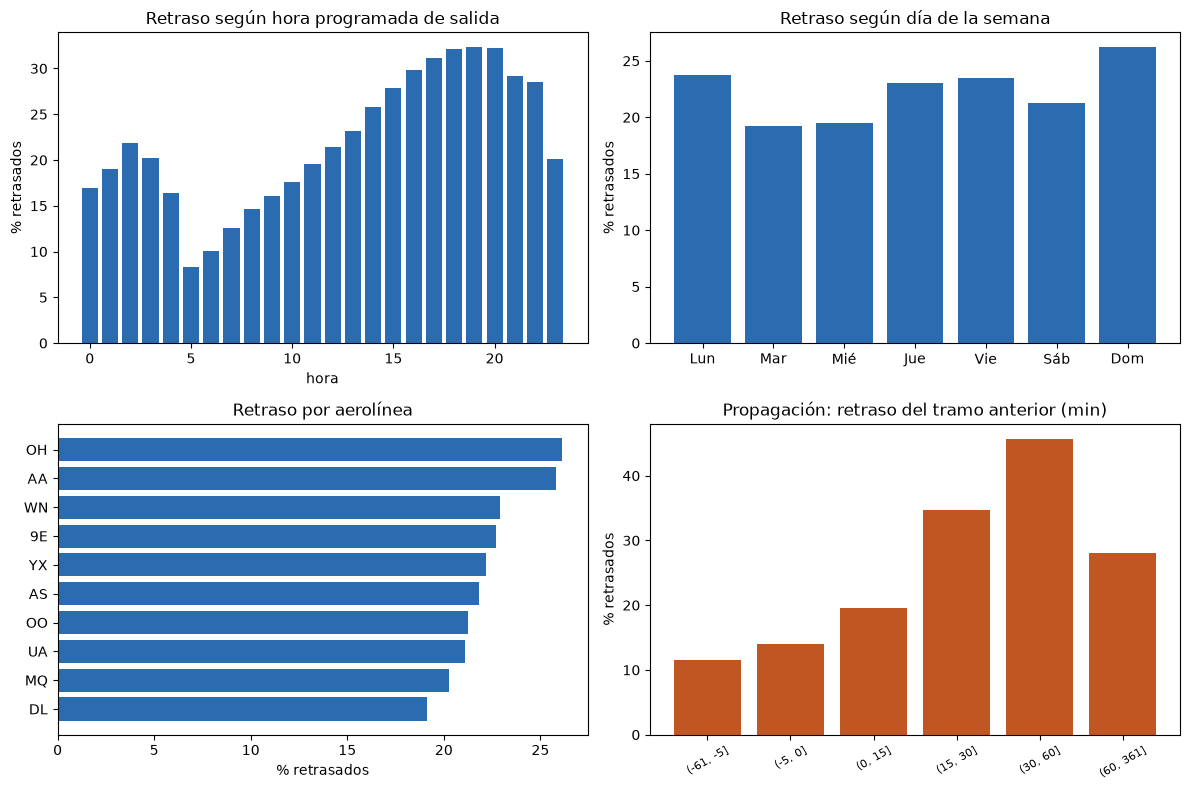

In [11]:
_ = evaluacion.grafica_hipotesis(tabla); plt.show()


---
## 5 · Modelos

Catálogo con familias distintas, no siete variantes del mismo árbol. Todas pasan por los mismos pliegues de `TimeSeriesSplit` y por el mismo `Pipeline` (imputación + escalado opcional + `TargetEncoder`). El umbral de decisión NO es 0,50: se busca maximizando el F1 del retraso en el ÚLTIMO pliegue de validación. Nunca se toca con la prueba.

Partición temporal:
- **Entrenamiento + validación** = los primeros 85 % del calendario, ordenados por fecha.
- **Prueba final** = el último 15 % del calendario. Se mira UNA sola vez al final.

Dentro del entrenamiento, `TimeSeriesSplit` arma 3 pliegues en los que el entrenamiento es siempre anterior en el tiempo al bloque de validación.

In [12]:
tabla = tabla.sort_values("fecha").reset_index(drop=True)
corte = int(len(tabla) * (1 - cfg.FRACCION_PRUEBA))
train, test = tabla.iloc[:corte], tabla.iloc[corte:]

# En modo rápido subsampleamos para que la exposición termine en pocos minutos.
if cfg.N_CV and len(train) > cfg.N_CV:
    train_cv = train.sample(cfg.N_CV, random_state=cfg.SEMILLA).sort_values("fecha")
else:
    train_cv = train
if cfg.N_TEST and len(test) > cfg.N_TEST:
    test = test.sample(cfg.N_TEST, random_state=cfg.SEMILLA).sort_values("fecha")

print(f"Entrenamiento (CV)   : {len(train_cv):,} filas | tasa retraso {train_cv[cfg.OBJETIVO].mean():.4f}")
print(f"Prueba final (reserva): {len(test):,} filas | tasa retraso {test[cfg.OBJETIVO].mean():.4f}")
print(f"Corte temporal        : {train.fecha.max().date()} → {test.fecha.min().date()}")

X_tr = columnas.armar_X(train_cv); y_tr = train_cv[cfg.OBJETIVO].to_numpy()
X_te = columnas.armar_X(test);     y_te = test[cfg.OBJETIVO].to_numpy()


Entrenamiento (CV)   : 60,000 filas | tasa retraso 0.2263
Prueba final (reserva): 200,000 filas | tasa retraso 0.2053
Corte temporal        : 2026-04-09 → 2026-04-09


### 5.1 · Calibrar la regla a mano (con entrenamiento, no con la prueba)

Buscamos la hora `HH` que maximiza el F1 cuando la regla dice «se retrasa si sale a las HH:00 o después».

In [13]:
hora_regla, f1_regla_tr = modelos.calibrar_regla(train_cv["hora_sal_dec"], y_tr)
print(f"Regla a mano calibrada: hora de corte = {hora_regla}  ·  F1 entrenamiento = {f1_regla_tr:.3f}")


Regla a mano calibrada: hora de corte = 12  ·  F1 entrenamiento = 0.406


### 5.2 · Comparar las familias con la misma validación

Mismos pliegues, mismo preprocesamiento, misma métrica (AUC). Se reporta AUC medio ± desviación, PR-AUC medio y las métricas del último pliegue (F1, Recall, Precisión) con el umbral óptimo.

In [14]:
comp = modelos.comparar_modelos(X_tr, y_tr, hora_regla=hora_regla, k=cfg.K_PLIEGUES)
display(comp.round(4))
comp.to_csv(cfg.RESULTADOS / "tabla_modelos_cv.csv")


  Línea base (siempre a tiempo)    AUC 0.5000  F1 0.000  (0 s)
  Regla a mano                     AUC 0.5794  F1 0.381  (0 s)
  Regresión logística              AUC 0.7367  F1 0.511  (1 s)
  Árbol de decisión                AUC 0.7813  F1 0.593  (1 s)
  Random forest                    AUC 0.7943  F1 0.593  (5 s)
  HistGradientBoosting             AUC 0.7989  F1 0.599  (3 s)
  Red neuronal (MLP)               AUC 0.7823  F1 0.580  (11 s)
  XGBoost                          AUC 0.7964  F1 0.600  (4 s)


,AUC,AUC_std,PR-AUC,F1,Recall,Precisión,Exactitud,umbral,seg
modelo,,,,,,,,,
HistGradientBoosting,0.7989,0.0064,0.6578,0.5993,0.5634,0.6401,0.8369,0.3173,3.0
XGBoost,0.7964,0.0079,0.6543,0.6003,0.5797,0.6223,0.8328,0.3118,3.7
Random forest,0.7943,0.0074,0.6447,0.5928,0.5388,0.6589,0.8397,0.3331,4.7
Red neuronal (MLP),0.7823,0.0100,0.6225,0.5799,0.5354,0.6324,0.8320,0.3225,10.9
Árbol de decisión,0.7813,0.0097,0.6325,0.5927,0.5862,0.5993,0.8255,0.2745,1.3
Regresión logística,0.7367,0.0063,0.5523,0.5114,0.4415,0.6076,0.8173,0.2945,1.2
Regla a mano,0.5794,0.0105,0.2424,0.3805,0.7010,0.2612,0.5058,0.5000,0.1
Línea base (siempre a tiempo),0.5000,0.0000,0.2105,0.0000,0.0000,0.0000,0.7835,0.5000,0.2


### 5.3 · Elegir el modelo

**Regla de desempate**, fijada ANTES de mirar la prueba:
> Entre los modelos cuyo AUC esté dentro de **una desviación típica** del mejor, gana el **más simple**.

Es la respuesta directa a *«no siempre gana el número más alto»*. Previene elegir un modelo complejo por una ventaja que podría ser ruido entre pliegues.

In [15]:
elegido, umbral, texto = modelos.elegir_modelo(comp, hora_regla=hora_regla)
print(texto)


Mejor AUC          : HistGradientBoosting (0.7989)
Margen (1 desv.)   : 0.0064
Empatados dentro del margen: ['HistGradientBoosting', 'XGBoost', 'Random forest']

-> Modelo elegido  : HistGradientBoosting
Umbral de decisión : 0.317  (máximo F1 en validación, nunca en la prueba)

Ventaja sobre la regla a mano en validación: +0.220 de AUC · +0.219 de F1


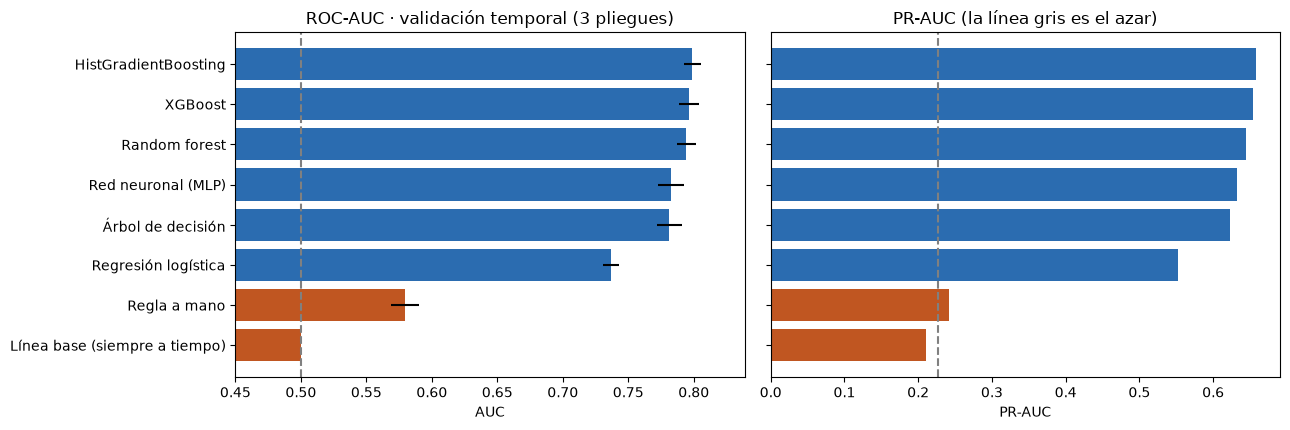

In [16]:
_ = evaluacion.grafica_comparacion(comp, float(y_tr.mean()), modelos.REFERENCIAS); plt.show()


---
## 6 · Evaluación

Reentrenamos el modelo elegido con **todo el entrenamiento** y lo tocamos **una sola vez** sobre la prueba. El umbral viene del último pliegue de validación: no se recalibra con la prueba.

In [17]:
t0 = time.time()
pipe = modelos.construir(elegido, hora_regla=hora_regla).fit(X_tr, y_tr)
p_test = pipe.predict_proba(X_te)[:, 1]
p_regla = modelos.ReglaManual(hora=hora_regla).fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
print(f"Entrenamiento final + predicción prueba: {time.time()-t0:.1f} s")

tabla_test = evaluacion.evaluar_prueba(y_te, p_test, umbral, elegido, p_regla, float(y_tr.mean()))
display(tabla_test)
tabla_test.to_csv(cfg.RESULTADOS / "tabla_prueba_final.csv")


Entrenamiento final + predicción prueba: 2.2 s


,AUC,PR-AUC,F1,Recall,Precisión,Exactitud
modelo,,,,,,
HistGradientBoosting,0.8086,0.6679,0.5913,0.5464,0.6443,0.8450
Regla a mano,0.5997,0.2467,0.3861,0.7384,0.2614,0.5180
Línea base (siempre a tiempo),0.5000,0.2053,0.0000,0.0000,0.0000,0.7947


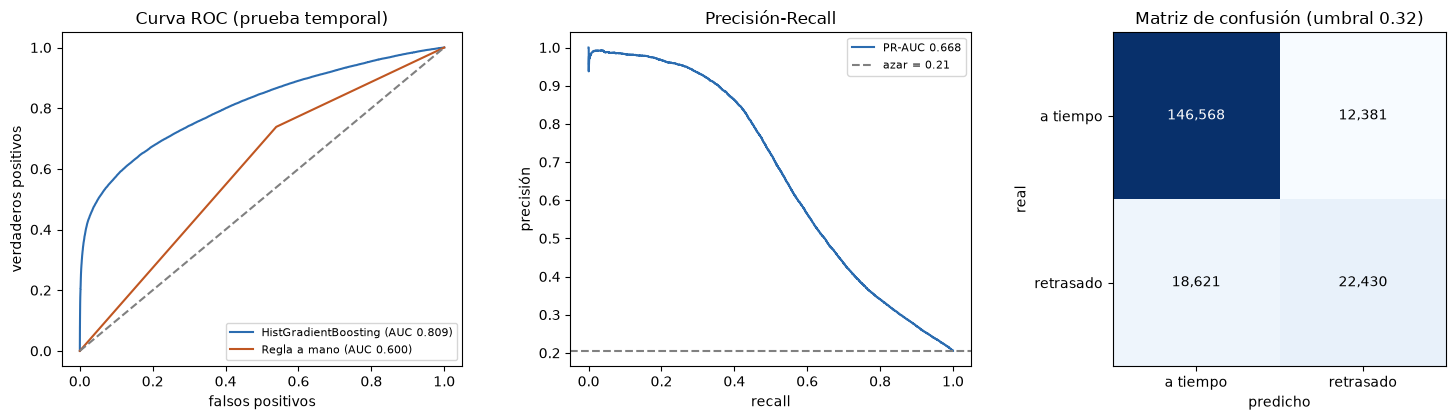

Matriz de confusión:
 [[146568  12381]
 [ 18621  22430]]


In [18]:
fig, cm = evaluacion.grafica_prueba(y_te, p_test, p_regla, umbral, elegido, tabla_test)
plt.show()
print("Matriz de confusión:\n", cm)


### 6.1 · Importancia por permutación

Se baraja una columna a la vez y se mide cuánto cae el AUC. Es agnóstica al tipo de modelo. Confirmamos que las columnas de rotación de la aeronave y de hora son las que más mueven el AUC.

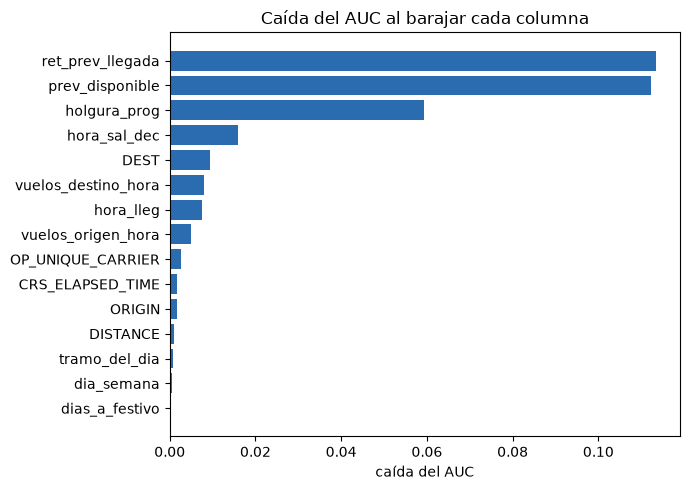

,caída AUC
ret_prev_llegada,0.1134
prev_disponible,0.1123
holgura_prog,0.0593
hora_sal_dec,0.0160
DEST,0.0095
vuelos_destino_hora,0.0080
hora_lleg,0.0076
vuelos_origen_hora,0.0049
OP_UNIQUE_CARRIER,0.0025
CRS_ELAPSED_TIME,0.0018


In [19]:
fig, imp = evaluacion.grafica_importancia(pipe, X_te, y_te)
plt.show()
display(imp.head(10).to_frame("caída AUC").round(4))
imp.to_frame("caida_AUC").to_csv(cfg.RESULTADOS / "importancia_columnas.csv")


### 6.2 · Guardar modelo y resumen reproducible

In [ ]:
joblib.dump({"pipeline": pipe, "umbral": umbral, "hora_regla": hora_regla,
             "elegido": elegido, "columnas_X": X_tr.columns.tolist()},
            cfg.MODELOS / "modelo_elegido.joblib")

resumen = {
    "problema": "Retraso de llegada >= 15 min, predicho a la hora de salida programada",
    "periodo": f"{cfg.MES_INICIO} a {cfg.MES_FIN}",
    "autores": cfg.AUTORES,
    "filas_tabla_modelado": int(len(tabla)),
    "tasa_retraso": float(tabla[cfg.OBJETIVO].mean()),
    "modo_rapido": bool(cfg.MODO_RAPIDO),
    "semilla": cfg.SEMILLA,
    "pliegues": cfg.K_PLIEGUES,
    "corte_temporal_prueba": str(test.fecha.min().date()),
    "modelo_elegido": elegido,
    "umbral": float(umbral),
    "regla_a_mano_hora": int(hora_regla),
    "AUC_cv_elegido": float(comp.loc[elegido, "AUC"]),
    "AUC_prueba_elegido": float(tabla_test.loc[elegido, "AUC"]),
    "AUC_prueba_regla": float(tabla_test.loc["Regla a mano", "AUC"]),
    "F1_prueba_elegido": float(tabla_test.loc[elegido, "F1"]),
    "F1_prueba_regla": float(tabla_test.loc["Regla a mano", "F1"]),
    "top3_columnas": {k: float(v) for k, v in imp.head(3).items()},
}
with open(cfg.RESULTADOS / "resumen_final.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False)
print(json.dumps(resumen, indent=2, ensure_ascii=False))


---
## Conclusiones

1. **El problema requiere ML.** La regla a mano calibrada (ver paso 5.1) deja un F1 muy por debajo del modelo elegido en la misma validación, y las columnas construidas por nosotros (rotación de la aeronave, congestión programada) son las que más mueven el AUC.
2. **El pre-vuelo basta para anticipar.** Solo con información del itinerario, el calendario, la congestión programada y la rotación del avión se obtiene un AUC muy superior al azar (0,50) y a la regla a mano.
3. **El umbral importa tanto como el modelo.** Con 20-25 % de retrasos, el 0,50 por defecto deja al modelo casi mudo. El umbral elegido en validación (ver resumen) sube el recall sin castigar demasiado la precisión.
4. **La fuga se demuestra, no se asume.** La celda del paso 4.4 mide el salto de AUC cuando `DEP_DELAY` entra al modelo: ese número NO se puede obtener en la vida real.
5. **Elección por simplicidad.** La regla «dentro de una desviación típica, gana el más simple» previene elegir un modelo complejo por una ventaja que podría ser ruido entre pliegues.
